<a href="https://colab.research.google.com/github/FarzanaAkter123/AI-Search-Algorithms/blob/main/IDDFS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Depth 0: ['A']
Depth 1: ['A', 'B', 'C']
Depth 2: ['A', 'B', 'D', 'E', 'C', 'F', 'G']
Depth 3: ['A', 'B', 'D', 'H']

IDDFS Result: ['A', 'B', 'D', 'H']
Goal Found: True
Goal Depth: 3


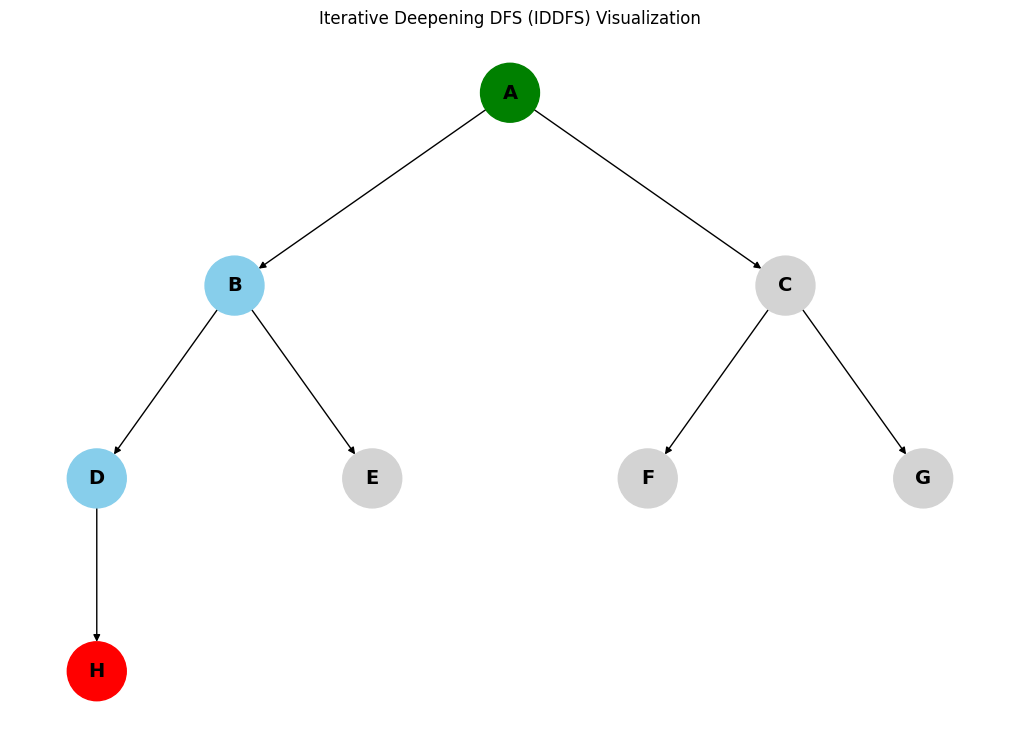

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a graph
graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F', 'G'],
    'D': ['H'],
    'E': [],
    'F': [],
    'G': [],
    'H': []
}

# Depth Limited Search
def dls(graph, node, goal, limit, depth=0, visited=None):

    if visited is None:
        visited = []

    visited.append(node)

    if node == goal:
        return True, visited

    if depth == limit:
        return False, visited

    for neighbor in graph[node]:

        found, visited = dls(
            graph, neighbor, goal,
            limit, depth + 1, visited
        )

        if found:
            return True, visited

    return False, visited


# IDDFS Algorithm
def iddfs(graph, start, goal, max_depth):

    for depth in range(max_depth + 1):

        found, visited = dls(
            graph, start, goal, depth
        )

        print(f"Depth {depth}: {visited}")

        if found:
            return True, visited, depth

    return False, visited, max_depth


# Run IDDFS
start_node = 'A'
goal_node = 'H'
max_depth = 4

found, result, depth = iddfs(
    graph, start_node, goal_node, max_depth
)

print("\nIDDFS Result:", result)
print("Goal Found:", found)
print("Goal Depth:", depth)


# Visualization
G = nx.DiGraph(graph)

pos = {
    'A': (0, 3),
    'B': (-1, 2),
    'C': (1, 2),
    'D': (-1.5, 1),
    'E': (-0.5, 1),
    'F': (0.5, 1),
    'G': (1.5, 1),
    'H': (-1.5, 0)
}

plt.figure(figsize=(10, 7))

node_colors = []

for node in G.nodes():

    if node == start_node:
        node_colors.append('green')

    elif node == goal_node and found:
        node_colors.append('red')

    elif node in result:
        node_colors.append('skyblue')

    else:
        node_colors.append('lightgray')


nx.draw(
    G,
    pos,
    with_labels=True,
    node_color=node_colors,
    node_size=1800,
    font_size=14,
    font_weight='bold',
    arrows=True
)

plt.title("Iterative Deepening DFS (IDDFS) Visualization")
plt.show()